# Fake News Detection: Model Development and Analysis

This notebook builds and compares models that classify news articles from the ISOT Fake News dataset as real or
fake: simple baselines, TF-IDF models with grid search, and a fine-tuned BERT model.

The EDA showed that the dataset contains **shortcuts**: traces of *where* an article was published rather than
whether it is true. Every real article comes from Reuters and starts with a dateline such as "WASHINGTON
(Reuters) -", the fake articles carry image credits, links and Twitter handles from their websites, the
`subject` categories of the two classes do not overlap at all, and thousands of fake articles are duplicates.
A model can reach almost 100 % accuracy from these alone. They are removed before modelling, and section 4.1
shows how much they inflated the results.

## 1. Setup and Imports

In [1]:
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from tqdm import tqdm

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from textblob import TextBlob

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, f1_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler, StandardScaler

import torch
from torch import nn
from torch.utils.data import DataLoader
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping
from transformers import BertModel, BertTokenizer

warnings.filterwarnings('ignore')
np.random.seed(42)
torch.manual_seed(42)
pl.seed_everything(42)
torch.set_float32_matmul_precision('high')

for package in ('punkt', 'punkt_tab', 'stopwords', 'wordnet'):
    nltk.download(package, quiet=True)

DATA_DIR = 'data'  # Fake.csv and True.csv from the ISOT Fake News dataset (see README)

## 2. Data Loading and Cleaning

Cleaning removes the source traces found in the EDA, so that the models have to work from the content and
writing of the articles:

1. **Reuters dateline**: the "CITY (Reuters) -" opening of every real article.
2. **Publisher and formatting markers**: URLs, `pic.twitter.com` links, Twitter handles, image credits
   ("Featured image via ...", "Getty Images"), site names such as "21st Century Wire", and the word "Reuters".
3. **Empty and duplicate texts**: duplicates would otherwise land in both the training and the test set.
4. **`subject` and `date`** are not used: the subject categories alone identify the class.

In [2]:
DATELINE = re.compile(r"^.{0,150}?\(Reuters\)\s*[-–]\s*", re.S)
SOURCE_MARKERS = re.compile("|".join([
    r"https?://\S+", r"\bpic\.twitter\.com/\S+", r"\bbit\.ly/\S+", r"@\w+",
    r"Featured image[^\n]*", r"(?:Photo|Image|Header image)\s*(?:by|via|credit|:)[^\n]*",
    r"\bGetty Images\b", r"\b21st Century Wire\b", r"\b21WIRE\b", r"\bReuters\b", r"\bvia YouTube\b",
]), re.I)


def strip_source(text):
    """Remove the dateline and publisher/formatting markers that reveal an article's source."""
    text = DATELINE.sub('', str(text))
    text = SOURCE_MARKERS.sub(' ', text)
    return re.sub(r'\s+', ' ', text).strip()


fake_df = pd.read_csv(os.path.join(DATA_DIR, 'Fake.csv'))
true_df = pd.read_csv(os.path.join(DATA_DIR, 'True.csv'))
fake_df['label'] = 0
true_df['label'] = 1
raw_df = pd.concat([fake_df, true_df], ignore_index=True)

markers = {'"(Reuters)" in the first 200 characters': r'\(Reuters\)', 'Featured image': r'Featured image',
           'Getty Images': r'Getty Images', 'pic.twitter.com link': r'pic\.twitter\.com', 'URL': r'https?://'}
print(pd.DataFrame({name: raw_df.groupby('label')['text'].apply(lambda s: s.str[:200 if 'first' in name else None]
                                                                 .str.contains(pat).mean() * 100)
                    for name, pat in markers.items()}).rename(index={0: 'fake (%)', 1: 'real (%)'}).round(1).T)

df = raw_df.copy()
df['title'] = df['title'].map(strip_source)
df['text'] = df['text'].map(strip_source)
n_empty = int((df['text'] == '').sum())
df = df[df['text'] != '']
n_dup = int(df['text'].duplicated().sum())
df = df.drop_duplicates('text').drop(columns=['subject', 'date']).reset_index(drop=True)
print(f"\n{len(raw_df):,} articles -> removed {n_empty:,} empty and {n_dup:,} duplicate texts -> {len(df):,} articles")
print(f"Real share after cleaning: {df['label'].mean():.1%}")

label                                    fake (%)  real (%)
"(Reuters)" in the first 200 characters       0.0      99.1
Featured image                               31.0       0.0
Getty Images                                 16.8       0.0
pic.twitter.com link                         14.8       0.0
URL                                          14.0       0.0



44,898 articles -> removed 725 empty and 5,594 duplicate texts -> 38,579 articles
Real share after cleaning: 54.9%


### 2.1 Text Preprocessing and Feature Engineering

- `preprocess_text` lower-cases the text, keeps letters only, removes stop words and lemmatises the words. The
  TF-IDF and count models use this cleaned text; BERT uses the original wording (after source cleaning).
- `extract_stylometric_features` describes the writing style: average word length, punctuation count, share of
  capital letters and sentiment polarity, separately for the title and the text.

In [3]:
STOP_WORDS = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text):
    """Clean and preprocess text data"""
    text = re.sub(r'[^a-zA-Z\s]', '', str(text).lower())
    tokens = [t for t in word_tokenize(text) if t not in STOP_WORDS]
    return ' '.join(LEMMATIZER.lemmatize(t) for t in tokens)


def extract_stylometric_features(text):
    """Extract stylometric features from text"""
    text = str(text)
    words = text.split()
    return {
        'avg_word_length': np.mean([len(w) for w in words]) if words else 0.0,
        'punctuation_count': len(re.findall(r'[.,!?;]', text)),
        'uppercase_ratio': sum(c.isupper() for c in text) / max(len(text), 1),
        'sentiment': TextBlob(text).sentiment.polarity,
    }


tqdm.pandas()
df['clean_title'] = df['title'].progress_apply(preprocess_text)
df['clean_text'] = df['text'].progress_apply(preprocess_text)
df['title_length'] = df['title'].str.len()
df['text_length'] = df['text'].str.len()

title_features = pd.DataFrame(df['title'].progress_apply(extract_stylometric_features).tolist()).add_prefix('title_')
text_features = pd.DataFrame(df['text'].progress_apply(extract_stylometric_features).tolist()).add_prefix('text_')
df = pd.concat([df, title_features, text_features], axis=1)
NUMERICAL_FEATURES = ['title_length', 'text_length'] + list(title_features.columns) + list(text_features.columns)

## 3. Train/Test Split and Baselines

The data is split once into a training set (80 %) and a test set (20 %), stratified by label. Everything is
fitted on the training set only, including the baselines:

- **Majority**: always predicts the most frequent class of the training set.
- **Title length**: fake titles are longer on average, so the rule predicts "fake" above a length threshold;
  the threshold is the one that works best on the training set.
- **Subject** (for comparison only): on the *uncleaned* data, predicting "real" for `politicsNews` and
  `worldnews` shows how strong this shortcut is. It is not used in any model.

In [4]:
X = df[['title', 'text', 'clean_title', 'clean_text'] + NUMERICAL_FEATURES]
y = df['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(f"Training set: {len(X_train):,} articles; test set: {len(X_test):,} articles")

results = {}


def record(name, y_true, y_pred, y_score=None):
    """Store comparable metrics for every model"""
    results[name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'ROC AUC': roc_auc_score(y_true, y_score) if y_score is not None else np.nan,
    }
    return results[name]


majority = DummyClassifier(strategy='most_frequent').fit(X_train[['title_length']], y_train)
record('Majority', y_test, majority.predict(X_test[['title_length']]))

thresholds = np.percentile(X_train['title_length'], np.arange(5, 100, 5))
best_t = max(thresholds, key=lambda t: accuracy_score(y_train, (X_train['title_length'] <= t).astype(int)))
record('Title length rule', y_test, (X_test['title_length'] <= best_t).astype(int), -X_test['title_length'])
print(f"Title length rule: titles up to {best_t:.0f} characters are predicted real")

raw_train, raw_test = train_test_split(raw_df, test_size=0.2, stratify=raw_df['label'], random_state=42)
subject_pred = raw_test['subject'].isin(['politicsNews', 'worldnews']).astype(int)
print(f"Subject rule on the uncleaned data (shortcut, not used): accuracy {accuracy_score(raw_test['label'], subject_pred):.4f}")

pd.DataFrame(results).T.round(4)

Training set: 30,863 articles; test set: 7,716 articles
Title length rule: titles up to 76 characters are predicted real
Subject rule on the uncleaned data (shortcut, not used): accuracy 1.0000


,Accuracy,Macro F1,ROC AUC
Majority,0.5492,0.3545,NaN
Title length rule,0.8306,0.8258,0.8778


After cleaning, real articles are the majority (54.9 %), so always predicting "real" gives 54.9 %. The title-length
rule (real if the title has at most 76 characters) already reaches 83.1 %. The subject rule reaches 100 % on the
uncleaned data, which is why the subject is left out.

## 4. Traditional ML Models with Grid Search

Titles and texts are vectorised separately (TF-IDF for logistic regression and random forest, word counts for
naive Bayes) and combined with the scaled stylometric features. Vectorisers and scalers are fitted on the
training set only. Hyperparameters are tuned with 3-fold cross-validation on the training set.

Logistic Regression: best {'C': 10.0}, test accuracy 0.9971


Naive Bayes: best {'alpha': 0.1}, test accuracy 0.9406


Random Forest: best {'max_depth': None, 'n_estimators': 100}, test accuracy 0.9949


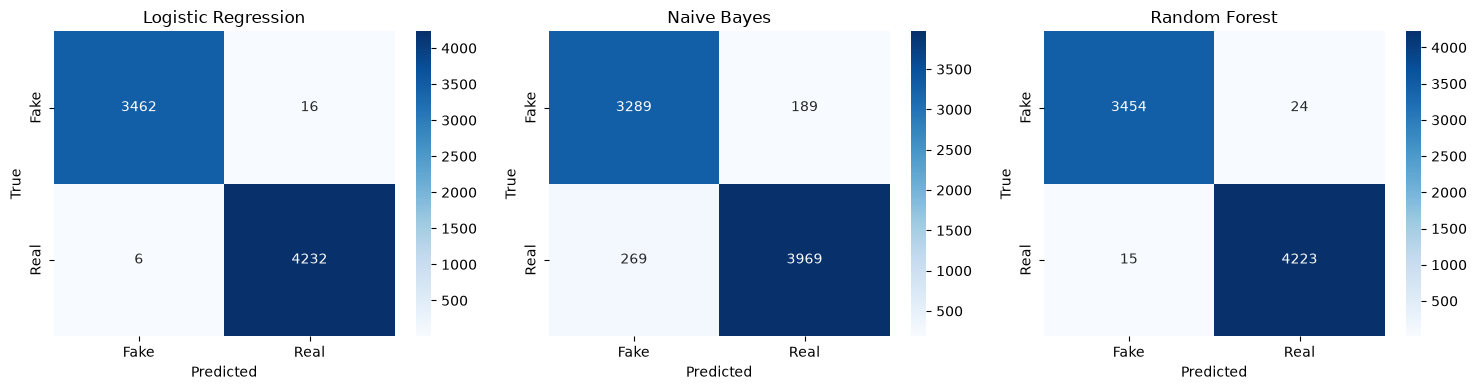

In [5]:
def prepare_features(X_train, X_test, model_type='tfidf'):
    """Vectorise titles and texts and add scaled numerical features (fitted on the training set only)"""
    if model_type == 'tfidf':
        title_vec, text_vec, scaler = TfidfVectorizer(max_features=5000), TfidfVectorizer(max_features=10000), StandardScaler()
    else:
        title_vec, text_vec, scaler = CountVectorizer(max_features=5000), CountVectorizer(max_features=10000), MinMaxScaler()
    parts_train = [title_vec.fit_transform(X_train['clean_title']), text_vec.fit_transform(X_train['clean_text']),
                   sp.csr_matrix(scaler.fit_transform(X_train[NUMERICAL_FEATURES]))]
    parts_test = [title_vec.transform(X_test['clean_title']), text_vec.transform(X_test['clean_text']),
                  sp.csr_matrix(scaler.transform(X_test[NUMERICAL_FEATURES]))]
    names = (['title: ' + w for w in title_vec.get_feature_names_out()] +
             ['text: ' + w for w in text_vec.get_feature_names_out()] + NUMERICAL_FEATURES)
    return sp.hstack(parts_train).tocsr(), sp.hstack(parts_test).tocsr(), names


X_train_tfidf, X_test_tfidf, tfidf_names = prepare_features(X_train, X_test, 'tfidf')
X_train_count, X_test_count, count_names = prepare_features(X_train, X_test, 'count')

models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42), {'C': [0.1, 1.0, 10.0]},
                            X_train_tfidf, X_test_tfidf),
    'Naive Bayes': (MultinomialNB(), {'alpha': [0.1, 0.5, 1.0]}, X_train_count, X_test_count),
    'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1),
                      {'n_estimators': [50, 100], 'max_depth': [5, 10, None]}, X_train_tfidf, X_test_tfidf),
}
fitted = {}
for name, (model, params, Xtr, Xte) in models.items():
    grid = GridSearchCV(model, params, cv=3, scoring='accuracy', n_jobs=-1).fit(Xtr, y_train)
    fitted[name] = grid.best_estimator_
    m = record(name, y_test, grid.predict(Xte), grid.predict_proba(Xte)[:, 1])
    print(f"{name}: best {grid.best_params_}, test accuracy {m['Accuracy']:.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (_, _, _, Xte)) in zip(axes, models.items()):
    sns.heatmap(confusion_matrix(y_test, fitted[name].predict(Xte)), annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.show()

Even on the cleaned data, logistic regression (99.7 %) and random forest (99.5 %) are almost perfect; naive Bayes
reaches 94.1 %.

### 4.1 How much did the shortcuts matter?

The same simple model (TF-IDF of the text with logistic regression) is trained on the uncleaned data and on the
cleaned data, each with a stratified 80/20 split.

In [6]:
def text_only_accuracy(frame, column='text'):
    tr, te = train_test_split(frame, test_size=0.2, stratify=frame['label'], random_state=42)
    vec = TfidfVectorizer(max_features=20000, sublinear_tf=True)
    clf = LogisticRegression(C=10, max_iter=2000).fit(vec.fit_transform(tr[column]), tr['label'])
    return accuracy_score(te['label'], clf.predict(vec.transform(te[column])))


shortcut_check = pd.DataFrame({
    'Test accuracy': {
        'Subject rule, uncleaned data': accuracy_score(raw_test['label'], subject_pred),
        'TF-IDF + LR, uncleaned text (with duplicates)': text_only_accuracy(raw_df),
        'TF-IDF + LR, cleaned text': text_only_accuracy(df),
        'TF-IDF + LR, cleaned titles only': text_only_accuracy(df, 'title'),
    }
})
shortcut_check.round(4)

,Test accuracy
"Subject rule, uncleaned data",1.0000
"TF-IDF + LR, uncleaned text (with duplicates)",0.9960
"TF-IDF + LR, cleaned text",0.9870
"TF-IDF + LR, cleaned titles only",0.9523


Removing the source traces and duplicates lowers the text-only model only from 99.6 % to 98.7 %. The models do not
need the explicit markers, because the two classes differ in writing style throughout, and a model that sees only
the titles still reaches 95.2 %. The full logistic regression model in section 4 (99.7 %) scores higher than this
text-only model because it also uses the titles and stylometric features such as capitalisation.

## 5. BERT

`bert-base-uncased` is fine-tuned on the title and text (source-cleaned, original wording, first 256 tokens),
with 20 % of the training set held out for validation and early stopping. The test set is the same as for the
other models.

In [7]:
class FakeNewsDataset(torch.utils.data.Dataset):
    def __init__(self, texts, titles, labels, tokenizer, max_length=256):
        self.texts, self.titles, self.labels = texts, titles, labels
        self.tokenizer, self.max_length = tokenizer, max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(str(self.titles[idx]), str(self.texts[idx]), max_length=self.max_length,
                                  padding='max_length', truncation=True, return_tensors='pt')
        return {'input_ids': encoding['input_ids'].flatten(),
                'attention_mask': encoding['attention_mask'].flatten(),
                'labels': torch.tensor(self.labels[idx], dtype=torch.long)}


class FakeNewsClassifier(pl.LightningModule):
    def __init__(self, n_classes=2, learning_rate=2e-5):
        super().__init__()
        self.save_hyperparameters()
        self.bert = BertModel.from_pretrained('bert-base-uncased')
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(self.bert.config.hidden_size, n_classes)
        self.learning_rate = learning_rate

    def forward(self, input_ids, attention_mask):
        output = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(self.dropout(output.pooler_output))

    def step(self, batch, stage):
        logits = self(batch['input_ids'], batch['attention_mask'])
        loss = nn.functional.cross_entropy(logits, batch['labels'])
        acc = (logits.argmax(dim=1) == batch['labels']).float().mean()
        self.log(f'{stage}_loss', loss, prog_bar=True, batch_size=len(logits))
        self.log(f'{stage}_acc', acc, prog_bar=True, batch_size=len(logits))
        return loss

    def training_step(self, batch, batch_idx):
        return self.step(batch, 'train')

    def validation_step(self, batch, batch_idx):
        return self.step(batch, 'val')

    def configure_optimizers(self):
        no_decay = ['bias', 'LayerNorm.weight']
        groups = [{'params': [p for n, p in self.named_parameters() if not any(nd in n for nd in no_decay)],
                   'weight_decay': 0.01},
                  {'params': [p for n, p in self.named_parameters() if any(nd in n for nd in no_decay)],
                   'weight_decay': 0.0}]
        return torch.optim.AdamW(groups, lr=self.learning_rate)


X_bert_train, X_val, y_bert_train, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train,
                                                            random_state=42)
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
make_loader = lambda Xp, yp, shuffle: DataLoader(
    FakeNewsDataset(Xp['text'].values, Xp['title'].values, yp.values, tokenizer),
    batch_size=16, shuffle=shuffle, num_workers=0, pin_memory=True)
train_loader = make_loader(X_bert_train, y_bert_train, True)
val_loader = make_loader(X_val, y_val, False)
test_loader = make_loader(X_test, y_test, False)

bert_model = FakeNewsClassifier()
trainer = pl.Trainer(max_epochs=2, accelerator='auto', devices=1, precision='16-mixed',
                     callbacks=[EarlyStopping(monitor='val_loss', patience=1, mode='min')],
                     enable_progress_bar=False, logger=False, enable_checkpointing=False)
trainer.fit(bert_model, train_loader, val_loader)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
bert_model = bert_model.to(device).eval()
bert_scores = []
with torch.no_grad(), torch.autocast(device_type=device, enabled=device == 'cuda'):
    for batch in test_loader:
        logits = bert_model(batch['input_ids'].to(device), batch['attention_mask'].to(device))
        bert_scores.extend(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
bert_scores = np.array(bert_scores)
bert_preds = (bert_scores >= 0.5).astype(int)
record('BERT', y_test, bert_preds, bert_scores)
print(classification_report(y_test, bert_preds, target_names=['Fake', 'Real'], digits=4))

              precision    recall  f1-score   support

        Fake     0.9986    0.9980    0.9983      3478
        Real     0.9983    0.9988    0.9986      4238

    accuracy                         0.9984      7716
   macro avg     0.9985    0.9984    0.9984      7716
weighted avg     0.9984    0.9984    0.9984      7716



BERT reaches 99.8 % accuracy, about 12 errors in 7,716 test articles, slightly better than logistic regression at a
much higher computational cost.

## 6. Model Comparison

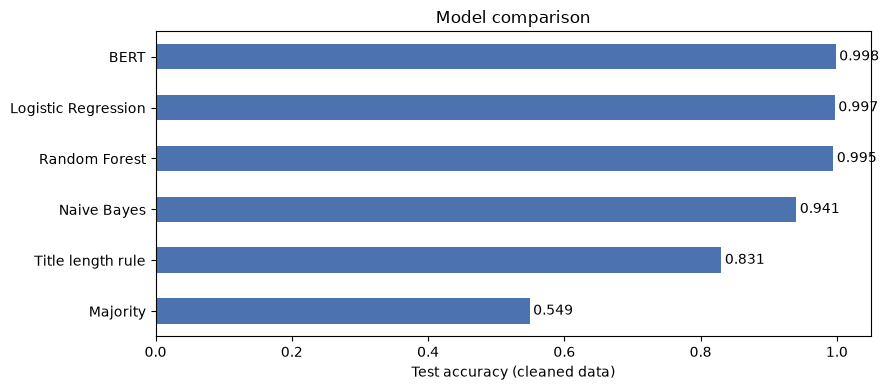

,Accuracy,Macro F1,ROC AUC
BERT,0.9984,0.9984,1.0000
Logistic Regression,0.9971,0.9971,0.9998
Random Forest,0.9949,0.9949,0.9998
Naive Bayes,0.9406,0.9402,0.9745
Title length rule,0.8306,0.8258,0.8778
Majority,0.5492,0.3545,NaN


In [8]:
comparison = pd.DataFrame(results).T.sort_values('Accuracy', ascending=False)
ax = comparison['Accuracy'].plot.barh(figsize=(9, 4), color='#4c72b0')
ax.invert_yaxis()
ax.set_xlim(0, 1.05)
ax.set_xlabel('Test accuracy (cleaned data)')
for i, v in enumerate(comparison['Accuracy']):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.title('Model comparison')
plt.tight_layout()
plt.show()
comparison.round(4)

## 7. Error Analysis

Misclassified test articles of the logistic regression model, with the start of their (cleaned) text.

In [9]:
lr_pred = fitted['Logistic Regression'].predict(X_test_tfidf)
wrong = X_test[lr_pred != y_test.values]
print(f"Logistic regression misclassified {len(wrong)} of {len(X_test):,} test articles\n")
for (idx, row), true_label in zip(wrong.head(5).iterrows(), y_test[wrong.index][:5]):
    print(f"True: {'Real' if true_label == 1 else 'Fake'} | Title: {row['title'][:120]}")
    print(f"   {row['text'][:250]} ...\n")

Logistic regression misclassified 22 of 7,716 test articles

True: Fake | Title: Exposing the Shakespearean tragedy of the “Russia Hacking” hoax
   Sunday Wire host Patrick Henningsen delivers another blow to the Resistance exposing the Shakespearean tragedy of the Russia Hacking hoax and explains why Hillary Rodham Clinton might have very well been one of the worse presidential candidates in US ...

True: Fake | Title: Is Hillary’s Meltdown Real, or a Staged Exit?
   says As shocking and controversial as Hillary Clinton s recent public health incident may seem, there s something oddly convenient about the near perfect proximity and position of the viral video footage, as well as other scenes like her nurse assist ...

True: Fake | Title: Jimmy Carter: ‘Koreans Want Peace Treaty to Replace 1953 Ceasefire’
   says Reframing the current diplomatic crisis in North Korea is essential if genuine progress is to be made in diffusing the current tense situation.Former US President Jimmy Carter

Only 22 of 7,716 test articles are misclassified. The fake articles that are missed are mostly from 21st Century
Wire, which writes in a calmer, more news-like style (the "says" at the start of their texts is what remains after
removing the site name). The real articles that are missed quote other outlets, such as Politico, or use more
opinionated wording.

## 8. What the Models Rely On

The largest logistic regression coefficients show which words push a prediction towards "real" or "fake".

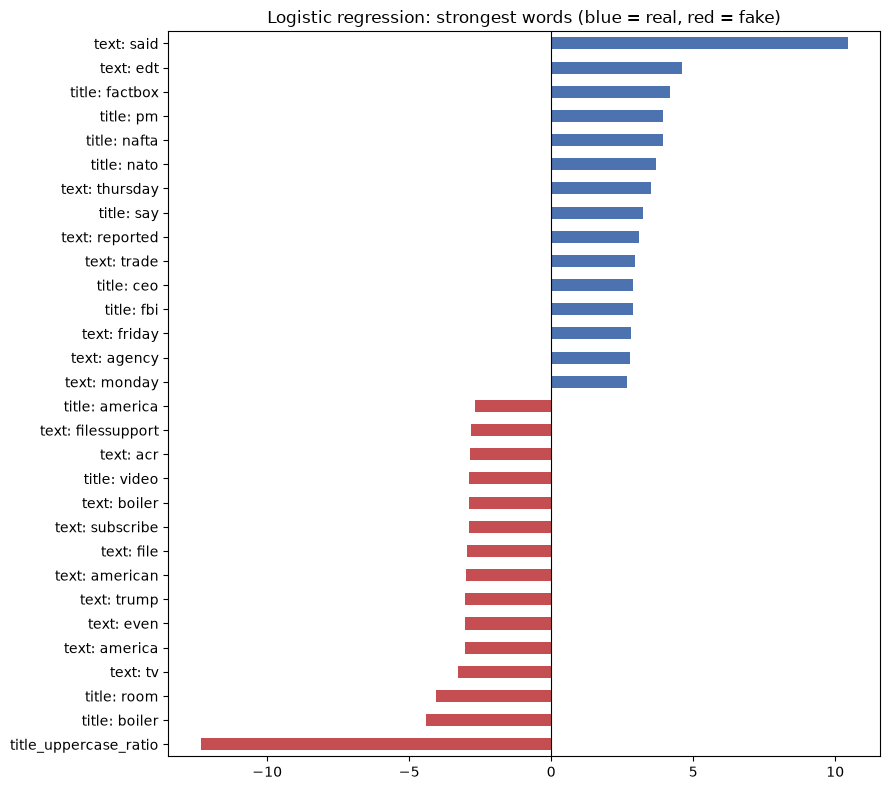

In [10]:
coef = pd.Series(fitted['Logistic Regression'].coef_[0], index=tfidf_names)
top = pd.concat([coef.nlargest(15), coef.nsmallest(15)]).sort_values()
plt.figure(figsize=(9, 8))
top.plot.barh(color=['#c44e52' if v < 0 else '#4c72b0' for v in top])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic regression: strongest words (blue = real, red = fake)')
plt.tight_layout()
plt.show()

The strongest signals are publisher habits rather than content. Reuters writes "said", gives times in EDT, uses
"Factbox" headlines and names the weekday ("on Thursday"). The fake-news sites write headlines in Title Case
(`title_uppercase_ratio`, the strongest feature of all), advertise their own shows ("Boiler Room") and ask readers to
"subscribe". These traces survive the cleaning because they are part of the writing itself.

## 9. Conclusions and Limitations

- On the ISOT dataset, real and fake articles can be told apart almost perfectly: on a held-out test set, after
  removing source traces and duplicates, BERT reaches 99.8 % accuracy, logistic regression 99.7 %, random forest
  99.5 % and naive Bayes 94.1 %.
- This mostly measures **source recognition, not fact-checking**. All real articles come from one news agency and
  all fake ones from a few websites, each with its own house style. The subject alone gives 100 %, and even after
  cleaning the strongest features are style habits such as headline capitalisation, "said" and weekday names.
- A model trained here is therefore unlikely to work on fake news from other sources, or to catch a false article
  written in a news-agency style.
- On this data a simple model is enough: logistic regression is within 0.2 percentage points of BERT at a
  fraction of the cost.
- An earlier version of this notebook trained on the uncleaned data (with the subject, the Reuters dateline and
  duplicates) and reported 99.9 % accuracy; those numbers reflected the shortcuts above.

**Next steps**
- Test the models on a different fake-news dataset, to measure how much of the accuracy is source style.
- Use data where real and fake articles come from similar outlets, or claim-level fact-checking data such as LIAR.
- Add temporal validation: train on older articles and test on newer ones.